# CYOA(choose your own adventure) Aprendizaje por refuerzo

Para esta práctica voy a tratar de hacer una red neuronal que sea capaz de recorrer y ganar adventuras de texto cyoa. Esas aventuras interactivas en la que hay un texto descriptivo de donde te encuentras y que hay, con múltiples opciones que puedes tomar, ya sea direcciones en las que viajar, si tomar o no objetos, enemigos etc. 


Para hacerlo la elección más apropiada me pareció desde el principio usar un **modelo de aprendizaje por refuerzo** ya que este tipo de historias son **escenarios deterministas** ,la opcion c siempre va a resultar en ir a la página x;  **discretos** o estas en el bosque de la página 20 o no, o tienes la llave del sótano, o no; la **exploración es uno de sus fundamentos**; **estados bien definidos** como tu localización y tu salud; y tiene **objetivos claros** que actúan muy bien **como recompensas** morir es recompensa -100000, ganar +100000, obtener objetos clave +100.



## Dataset

Una vez elegido que vamos a hacer hay que elegir que historias vamos a usar para entrenar y evaluar nuestro modelo. Inicialmente pensé en usar las crónicas del kai, una serie de aventuras de este tipo a las que yo jugué y que además tienen la ventaja de estar libres para usos no lucrativos en el proyecto Aon https://www.projectaon.org/en/Main/FlightFromTheDark donde se pueden descargar fácilmente.

Sin embargo, pronto me di cuenta de que usar estas como dataset acarraería muchos problemas:
Primero el formato en el que estan escritos necesitaría añadir un NLP para analizar el lenguaje para poder ver que opciones tiene.
Segundo hay una gran variedad de disciplinas que el personaje puede usar y levelear, que cambian de manera radical como enfocar la aventura, esto unido a que cada historia es un juego largo, con muchas derrotas, y "tiradas de dado" necesarias hace que sea un juego un pelín desafiante para un humano normal, mucho menos para una red neuronal que desarrolle yo. A mi nivel actual conseguir que se pase estas historias  me supondría un reto excesiivo.

Con esta opción descartada ví varias alternativas que también eran de licencia libre o que me permitirían generar de manera ayudad varias historias. https://github.com/dfabulich/choicescript me permitiría ser "developer" de este tipo de juegos y encontré https://www.microsoft.com/en-us/research/project/textworld/try-it/ que tiene múltiples historias de este tipo desarrolladas especiamente para machine learning. 

Pero ya que no voy ir con las crónicas del kai que sería el dataset externo más currado he decidido que voy a realizar mi propio datset de 3 historias de este tipo sin ayuda externa como la que menciono arriba para hacer que la práctica sea más individual y original.

Voy a usar formato Json con varios nodos, cada uno con tu inventario, un campo de texto, encuentro(objetos , enemigos) si lo hay, opciones a escojer, recompensa(negativa o positiva) de requerirlo. Haré tres historias(entrenamiento, y dos de validación)


In [ ]:
{
  "start": 1,
  "nodos": {
    "1": {
      "texto": "Te despiertas con un dolor de cabeza aún peor que la mañana después del banquete celebrando la victoria del valle del Jerto sobre esos condenados husitas, estes donde estes has debido de recibir un buen golpe en la cabeza",
      "encuentro": null,
      "objeto":null,
      "reward": 0,
      "fin": false,
      "opciones": {
        "fingir seguir inconsciente": 2,
        "levantarte y hacer acopio de tu situación": 3
      }
    },    

    "2": {
      "texto": "Justo después de incorporarte vislumbras una tenue luz que acaba de girar la esquina, su origen, un enorme carcelero con sonrisa cruel que nada más verte despierto llama refuerzos y juntos te llevan áun más profundo en la mazmorra...",
      "encuentro": null,
      "objeto":null,
      "reward": -500,
      "fin": false,
      "opciones": {"eres arrastrado hacia una sla de tortura":20}
    },

    "3": {
      "texto": "Entre el mínimo resquicio de tus ojos entrecerrados vislumbras una sombra portando una antorcha, esa luz te permite entrever unas piernas largas y gruesas con unas llaves al cinto afuera de una celda con barrotes, tras un breve rato  ves los pies girarse dandote la espalda, probablemente un carcelero husita encargado de vigilar la mazmorraen la que estes",
      "encuentro": null,
      "objeto":null,
      "reward": 10,
      "fin": false,
      "opciones": {
        "esperar hasta que el carcelero se marche a otro sitio, no veas la luz y hacer acopio de tu situación": 4,
        "levantarte a hurtadillas y tratar de quitarle las llaves": 19,
        "trata de llamar la atención del guardia, finjiendo necesitar atención médica pero preparandote para abalanzarte y atacar al guardia en cuanto entre a tu celda para mirar si estas bien": 18
      }
    },
    "4": {
          "texto": "esperas largos minutos hasta que el pasillo queda en completo silencio, lo primero que haces es comprobar si al arrebatarte todo lo que llevabas encima te quitaron tu diente falso, bien, parece que no te buscaron lo suficientemente bien y no detectaron el encantamiento realizado por un mago para romper atadura o abrir cualquier cerrojo una y una sola vez",
          "encuentro": null,
          "objeto":null,
          "reward": 5,
          "fin": false,
          "opciones": {
            "arrancate el diente y usalo sobre la puerta de barrotes de tu celda": 5
          }
        },
    "": {
      "texto": "olvidado al lado de la mesa a medio reparar entre clavos toscamente forjados vislumbras un martillo de carpintero",
      "encuentro": null,
      "objeto": null ,
      "reward": 10,
      "fin": false,
      "opciones": {
        "Coje el martillo,un arma al fin, bueno una herramienta que puede usarse como tal, mejor que tus manos desnudas desde luego": X,
        "No lo cojas puede que el carpintero simplemente se ausentase por un momento y al volver y descubrir el hurto de la voz de alarma, el sigilo es tu mejor arma": Y
    },
    "": {
      "texto": "martillo en mano, sales de la habitación",
      "encuentro": null,
      "objeto":"martillo",
      "reward": 600,
      "fin": false,
      "opciones": {
        "vuelve al pasillo": Z
      }
        
    },

    "15": {
      "texto": "Al girar la esquina te encuentras de bruces con el carcelero en frente de una maziza puerta de madera, parece que solo te queda luchar",
      "encuentro": "carcelero",
      "objeto":null,
      "reward": -1000,
      "fin": true,
      "opciones": {"atacar al carcelero": 16}
    },

    "16": {
      "texto": "das el primer paso y te abalanzas, la distancia se cierra en un suspiro, el carcelero alza la maza y el choque es inevitable",
      "encuentro": "carcelero",
      "objeto": null,
      "reward": 0,
      "fin": false,
      "opciones": {}
    },

    "17": {
      "texto": "Eres un paladin, caballero entre caballeros y el carcelero un simple hombre de armas, con una maza y buena armadura frente a tus manos desnudas, luchaste como un oso de tu tierra, pero eso solo permitió que el carcelero se viese forzado a matarte en vez de caer preso una vez más",
      "encuentro": null,
      "objeto":null,
      "reward": -1000,
      "fin": true,
      "opciones": {}
    },

    "18": {
      "texto": "El dolor de tu cabeza hace que no necesites fingir un gemido de dolor como si estuvieses moribundo, nunca sbrás si ese perro husita se olió una trampa o simplemente no le importaba tu estado, solo abrió la uerta tras llamar a gritos a más guardas para arrastrate a lo profundo de la mazmorra...",
      "encuentro": null,
      "objeto":null,
      "reward": -500,
      "fin": false,
      "opciones": {}
    },

    "19": {
      "texto": "El guarda pilla tu brazo extendiendose entre los barrotes infraganti y antes de que puedas reaccionar sientes el beso de una maza en tu antebrazo, y escuchas el grito de refuerzos del carcelero llamando a más compañeros para arrastrate a lo profundo de la mazmorra...",
      "encuentro": null,
      "objeto":null,
      "reward": -500,
      "fin": false,
      "opciones": {}
    },

    "20": {
      "texto": "... donde te espera un interrogador dispuesto a torturarte hasta que les cuentes la localización de la lanza del alba",
      "encuentro": null,
      "objeto":null,
      "reward": -1000,
      "fin": true,
      "opciones": {}
    },
    "21": {
      "texto": "El carcelero claramente es un hombre de armas, con buena malla, un solido casco  y una maza de guerra mientras tu solo tienes un martillo de carpintero, sin embargo sigues siendo un paladín y un martillo más apropiado para clavos te sigue permitiendo partir primero su codo y luego su cráneo pese a su casco. Tras darle muerte no pierdes el tiempo cojer su maza y su manojo de llaves, su malla demasiado pequeña para que pase si quiera tus hombros, empiezas a buscar en el manojo la llave que abra la puerta fuera de esta sección de mazmorras y un paso más cerca de la libertad",
      "encuentro": null,
      "objeto":null,
      "reward": 1000,
      "fin": true,
      "opciones": {}
    }
  }
}

Al hacerlo así no necesito un NLP(el texto es irrelevante para la maquina) y me aseguro de tener todo lo que busco incluido varios finales malos, un pelin de reward en cada nuevo nodo neutral y un objeto necesario para poder ganar asegurandome que el modelo ha de explorar de manera apropiada y cojer objetos para ganar.

Esto último es aí porque he decidido que en el enviroment al ver que el encuentro no es nulo comprobaré,en el 16 por ejemplo, si tienes o no el martillo y te mandará al 17 o al 21 en función de ello(lo normal en estas historias) .
El resto de nodos los completaré yo para asegurarme que esista un camino real hacia la victoriay el texto que lo rellene una IA una vez asegurado lo que quiero porque llevo más de lo que me gustaria admitir escribiendo esto ya que soy lector asiduo pero escribo solo código y exámenes, y ese tiempo será mejor usado provando variaciones del modelo o estudiando.

Crearé tambien otras dos aventuras mas para testear y validar, siendo la 2 un pelin más corta y similar a la 1, y la 3 más larga y más laberinto enfocado a orientarte más que buscar un objeto, que en este caso al cogerlo te mata.

# Cargar el dataset y preparar el enviroment

En el proceso de querer convertir mis json en un dataset entendible por la máquina me di cuenta de dos cosas. la primera que voy a tener que añadir un campo que indique si un nodo es un final o no para que al llegar a estos el modelo termine su run y pueda volver a empezar otra. 

Lo segundo es que el inventario lo va a tener que llevar el env para poder hacer la comprobación en el encuentro así que lo quitaré de mi json, también me he dado cuenta de que es más fácil usar encuentro para enemigos y objeto para objetos, así el enviroment no tendrá que distinguir además que tipo de encuentro es. También pongo el objeto en el nodo en el que ya se ha escogido cogerlo, de esta manera, solo se añadirá el objeto al inventario en el env una ves se halla decidido y no cuando te dan la opción al verlo por primera vez, ya que entonces el env tendría que monitorear que opción tomo la red. Aplico estos cambios a mis json y al ejemplo de arriba.

Una vez escito los json bien y con todo lo que necesito necesito transformarlos en un entorno en el que el agente(mi red neuronal) pueda interactuar como mis json ya son un marco casi idealMDP(proceso de decision de markov, es como se llama matemáticamente a este tipo de marcos),determinista, con las reward y exploracion; para Q learning teniendo ya S,A,R. S estado	(nodo, inventario),
A acciones (opciones), R recompensa	(recompensa)
Ahora lo rimero va a ser pas

In [1]:
 #para cargar las aventuras
import json
from dataclasses import dataclass
from pathlib import Path

#para construir el enviroment
import gymnasium as gym
from gymnasium import spaces
import numpy as np

#para el Q-learning
import random

In [2]:
#Estructura del nodo
@dataclass
class Nodo:
    texto: str
    encuentro: object
    objeto: object
    recompensa: float
    fin: bool
    opciones: dict   # {opcion: siguiente_estado}
    
#Estructura de la aventura conjunto de todos los nodos
@dataclass
class MDP_Aventura:    
    inicio: int                 
    nodos: dict                 

    estados: list               # Lista de todos los estados posibles (ids de nodos)
    acciones_por_estado: dict   # {estado: [acciones_texto_posibles]}
    transiciones: dict          # {(estado, accion_texto): siguiente_estado}
    recompensas_por_estado: dict# {estado: recompensa_del_estado}
    estados_terminales: dict    # {estado: True/False} indica si el episodio termina ahí

In [3]:
def cargar_aventura_mdp(aventura_json):
    inicio = int(aventura_json["start"])
    nodos_raw = aventura_json["nodos"]

    nodos = {}

    # Aquí relleno cada nodo con los datos del json, si en el json esos datos están vacíos, los pongo con valor por defecto
    for id_raw, data in nodos_raw.items():
        id_nodo = int(id_raw)

        texto = data.get("texto", "")
        encuentro = data.get("encuentro", None)
        objeto = data.get("objeto", None)
        recompensa = data.get("reward", 0)
        fin = bool(data.get("fin", False))
        opciones_raw = data.get("opciones", {}) or {}

        # Si el nodo no es final ni de encuentro, aseguramos que tenga opciones
        if not fin and not encuentro and len(opciones_raw) == 0:
            raise ValueError(f"El nodo {id_nodo} no tiene opciones válidas, pero no es un nodo final ni de encuentro.")

        # opciones es una lista de los siguientes estados
        opciones = [int(id_siguiente_nodo) for accion_texto, id_siguiente_nodo in opciones_raw.items()]
        nodos[id_nodo] = Nodo(texto, encuentro, objeto, recompensa, fin, opciones)
        
    # Compruebas si está bien, hay nodo de inicio, los nodos llevan a un nodo real
    if inicio not in nodos:
        raise ValueError("El nodo de inicio no existe")

    for id_nodo, nodo in nodos.items():
        for id_siguiente_nodo in nodo.opciones:
            if id_siguiente_nodo not in nodos:
                raise ValueError(f"Opción inválida: {id_nodo} --> {id_siguiente_nodo}")

    # Rellena el MDP aventura
    estados = sorted(nodos.keys())
    acciones_por_estado = {}
    transiciones = {}
    for id_estado in estados:
        # Almacenar las acciones como una lista
        acciones = nodos[id_estado].opciones
        acciones_por_estado[id_estado] = acciones
        for siguiente_estado in acciones:
            transiciones[(id_estado, siguiente_estado)] = siguiente_estado

    recompensas_por_estado = {id_estado: float(nodos[id_estado].recompensa) for id_estado in estados}
    estados_terminales = {id_estado: bool(nodos[id_estado].fin) for id_estado in estados}

    return MDP_Aventura(
        inicio, nodos,
        estados, acciones_por_estado, transiciones,
        recompensas_por_estado, estados_terminales
    )


In [4]:
aventura1 = cargar_aventura_mdp(json.load(open('aventura1.json')))
aventura2 = cargar_aventura_mdp(json.load(open('aventura2.json')))
aventura3 = cargar_aventura_mdp(json.load(open('aventura3.json')))
print(aventura1.acciones_por_estado[1])
print(aventura2.recompensas_por_estado[10])
print(aventura3.estados_terminales[25])

[2, 3]
10.0
True


Ahora vamos a crear el enviroment donde nuestro agente podrá tomar decisiones, aqui también gestionaremos el inventario y el encuentro con el carcelero

In [36]:
class Aventura1GymEnv(gym.Env):
    def __init__(self, mdp_aventura):
        super(Aventura1GymEnv, self).__init__()

        # Guardamos el MDP 
        self.mdp = mdp_aventura
        self.estado_actual = mdp_aventura.inicio

        # conjunto de todas las opciones posibles en el estado actual
        self.action_space = spaces.Discrete(len(mdp_aventura.acciones_por_estado[self.estado_actual]))

        # conjunto de nodos (estados)
        self.observation_space = spaces.Discrete(len(mdp_aventura.estados))

        self.inventario = []

    def reiniciar(self):
        self.estado_actual = self.mdp.inicio
        self.inventario = []
        return self.estado_actual

    def step(self, action):        
        # Imprimir estado actual y opciones disponibles
        print(f"Estado actual: {self.estado_actual}")
        print(f"Acciones disponibles: {self.mdp.acciones_por_estado[self.estado_actual]}")
        print(f"Tamaño del action_space: {self.action_space.n}")

        

        # Verificar si el estado actual es terminal antes de tomar acción
        if self.mdp.estados_terminales.get(self.estado_actual, False):
            recompensa = self.mdp.recompensas_por_estado[self.estado_actual]
            print(f"Estado final alcanzado: {self.estado_actual}, Recompensa: {recompensa}")
            return self.estado_actual, recompensa, True, {}

        fin = False

        # Verificar si hay un objeto en el estado actual y añadirlo al inventario (automáticamente)
        objeto = self.mdp.nodos[self.estado_actual].objeto
        if objeto and objeto not in self.inventario:
            self.inventario.append(objeto)
            print(f"Objeto recogido: {objeto}")

        
        
        accion_texto = self.mdp.acciones_por_estado[self.estado_actual][action]

        # Obtenemos el siguiente estado y recompensa
        siguiente_estado = self.mdp.transiciones[(self.estado_actual, accion_texto)]
        #si el siguiente tiene encuentro y ese encuentro es el del carcelero mira si tengo el martillo, en funcion de eso me manda a victoria o derrota
        #se tiene que hacer asi de cutre personalmente y mirando el estado siguiente para que el puto python de los huevos si o si ejecute esto del env
        # antes de que el agente pida las opciones en medio de la "ejecucion paralela" de env y agente porque le salga de la punta de la polla
        if self.mdp.nodos[siguiente_estado].encuentro is not None:
            if self.mdp.nodos[siguiente_estado].encuentro == "carcelero":
                if "martillo" in self.inventario:
                    siguiente_estado = 21
                else:
                    siguiente_estado = 17
        
        print(f"Acción seleccionada: {accion_texto}, Siguiente estado: {siguiente_estado}")

        # Obtener la recompensa para el siguiente estado
        recompensa = self.mdp.recompensas_por_estado[siguiente_estado]

        # Actualizamos el estado actual
        self.estado_actual = siguiente_estado
        return self.estado_actual, recompensa, fin, {}

    def render(self):
        print(f"Estado actual: {self.estado_actual}")
        print(self.mdp.nodos[self.estado_actual].texto)


# Q learning con política epsilon greedy

Ahora que tengo un entorno ya hecho, voy a proceder con mi agente, como ya he mencionado un MDP es perfecto para RL, como en este de historias el largo plazo es super importante, literalmente es una mini campaña con un unico objetivo a largo plazo y obstaculos en el camino para que no lo consigas; voy a usar q learning ya que es un algoritmo que valora muy bien eso. En cuanto a política voy a usar epsilon greedy para poder alternar entre explorar nuevas opciones y explotar las que ya se que son nuevas.

In [37]:
class QLearningAgent:
    def __init__(self, env, alpha=0.1, gamma=0.9, epsilon=0.1):
        self.env = env
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

        n_estados = env.observation_space.n
        max_acciones = max(len(self.env.mdp.acciones_por_estado[s]) for s in self.env.mdp.estados)
        self.q_table = np.zeros((n_estados, max_acciones))


    def seleccionar_accion(self, estado):

        # Para que no pida accion en estados finales
        if self.env.mdp.estados_terminales.get(estado, False):
            return None

        opciones = self.env.mdp.acciones_por_estado[estado]
        estado_index = estado - 1

        if random.uniform(0,1) < self.epsilon:
            return random.randrange(len(opciones))
        else:
            return np.argmax(self.q_table[estado_index][:len(opciones)])


    def actualizar_q(self, estado, accion, recompensa, siguiente_estado):
        estado_index = estado - 1
        siguiente_estado_index = siguiente_estado - 1

        max_q_siguiente = np.max(self.q_table[siguiente_estado_index])
        self.q_table[estado_index, accion] += self.alpha * (
            recompensa + self.gamma * max_q_siguiente - self.q_table[estado_index, accion]
        )


    def entrenar(self, episodios):
        for episodio in range(episodios):
            estado = self.env.reiniciar()
            done = False

            while not done:
                accion = self.seleccionar_accion(estado)

                if accion is None:
                    break

                siguiente_estado, recompensa, done, _ = self.env.step(accion)
                self.actualizar_q(estado, accion, recompensa, siguiente_estado)
                estado = siguiente_estado

                if episodio % 100 == 0:
                    print(f"Capítulo {episodio}, Estado: {estado}, Recompensa: {recompensa}")

Con el agente creado vo a entrenarlo 500 episodios en el env para la aventura 1. me saldrán muchos errores en el env que iré corrigiendo al hacer esto, no voy a poner los cambios o el notebook sera inmnso , simplemente ire actualizando el env

In [63]:
mdp_aventura = cargar_aventura_mdp(json.load(open('Aventura1.json')))
env = Aventura1GymEnv(mdp_aventura)


agente = QLearningAgent(env)

# Entrenar al agente
agente.entrenar(episodios=1000)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: -500.0
Estado actual: 2
Acciones disponibles: [20]
Tamaño del action_space: 2
Acción seleccionada: 20, Siguiente estado: 20
Capítulo 0, Estado: 20, Recompensa: -1000.0
Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 3, Siguiente estado: 3
Estado actual: 3
Acciones disponibles: [4, 19, 18]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Estado actual: 4
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Estado actual: 6
Acciones disponibles: [7, 8]
Tamaño del action_space: 2
Acción seleccionada: 7, Siguiente estado: 7
Estado actual: 7
Acciones disponibles: [8, 9]
Tamaño del action_space: 2
Objeto recogido: gra

Ahora que al fin tengo un agente funcional voy a recopilar la media y estadisticas de la curva de aprendizaje y a mostrarl en un gráfico

In [43]:
import matplotlib.pyplot as plt

In [60]:
def evaluar_curva(env, agente, pasos=1500):
    estado = env.reiniciar()
    total = 0
    medias = []

    # evaluación SIN exploración
    epsilon_backup = agente.epsilon
    agente.epsilon = 0.0

    for i in range(pasos):
        accion = agente.seleccionar_accion(estado)

        if accion is None:
            estado = env.reiniciar()
            continue

        siguiente, r, done, _ = env.step(accion)
        total += r
        medias.append(total / (i+1))

        estado = siguiente
        if done:
            estado = env.reiniciar()

    agente.epsilon = epsilon_backup
    return np.array(medias)

In [64]:
agente = QLearningAgent(env, epsilon=0.1)
agente.entrenar(episodios=1000)

curva = evaluar_curva(env, agente, pasos=1500)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: -500.0
Estado actual: 2
Acciones disponibles: [20]
Tamaño del action_space: 2
Acción seleccionada: 20, Siguiente estado: 20
Capítulo 0, Estado: 20, Recompensa: -1000.0
Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 3, Siguiente estado: 3
Estado actual: 3
Acciones disponibles: [4, 19, 18]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Estado actual: 4
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Estado actual: 6
Acciones disponibles: [7, 8]
Tamaño del action_space: 2
Acción seleccionada: 7, Siguiente estado: 7
Estado actual: 7
Acciones disponibles: [8, 9]
Tamaño del action_space: 2
Objeto recogido: gra

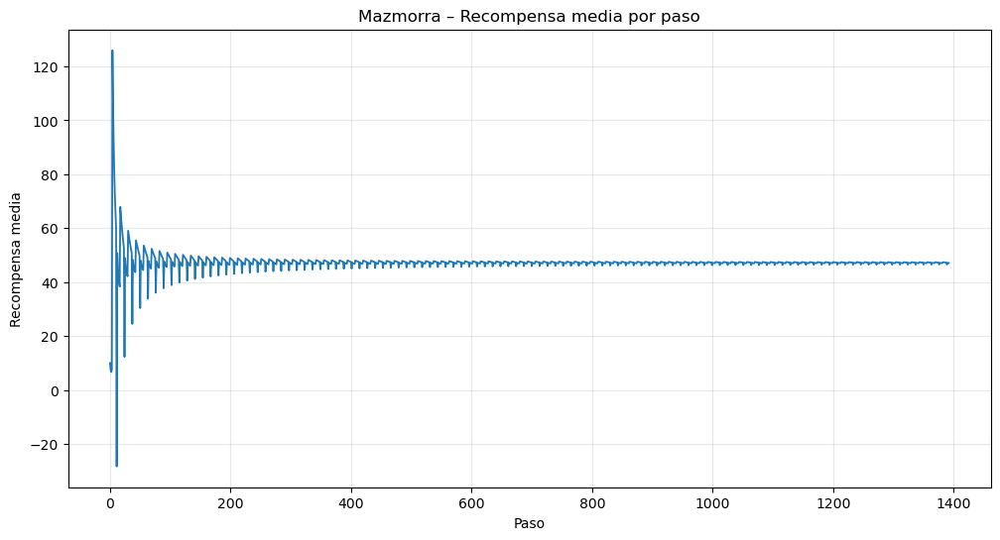

In [62]:
plt.figure(figsize=(12,6))
plt.plot(curva, lw=1.3)
plt.title("Mazmorra – Recompensa media por paso")
plt.xlabel("Paso")
plt.ylabel("Recompensa media")
plt.grid(alpha=0.3)
plt.show()

Aqui vemos que en apenas unos  cientos de pasos se empieza a estabilizar la recompensa media ya que tras unos pocos pasos encuentra el camino optimo y entonces la media se estanca enla recompensa del camino optimo(unos 1400 de reward) y cuantos runs a hecho, con el error ocasional forzado por explorar debido al epsilon de 0,1, he hecho una grafica parecida pero que muestre solo la recompensa por episodio pero es basicamente lo mismo, también he tocado el epsilon para que explore mas o menos perso si lo subes al final empeora porque no hace que encuentre el camino optimo mucho más rápido y fuerza errores por explorar.

# Pruebas con las otras dos aventuras

Ahora creare los enviroments para la aventura2 que tiene que ser diferente debido a un encuentro no determinista(sobrevives tambien si tienes un objeto o no) y ha como python maneja el enviroment en paralelo al agente. podría haber hecho un enviroment para todo mi dataset con un switch pero me parece mas elegante tener un env para cada historia igual que si esta red se pasase pokemons cambiarias de envs con cada juego , la comparación es similar pese a la diferencia de calidad y profundidad en datasets/red de bots que se pasn pokemons

In [68]:
class Aventura2GymEnv(gym.Env):
    def __init__(self, mdp_aventura):
        super(Aventura2GymEnv, self).__init__()

        # Guardamos el MDP 
        self.mdp = mdp_aventura
        self.estado_actual = mdp_aventura.inicio

        # conjunto de todas las opciones posibles en el estado actual
        self.action_space = spaces.Discrete(len(mdp_aventura.acciones_por_estado[self.estado_actual]))

        # conjunto de nodos (estados)
        self.observation_space = spaces.Discrete(len(mdp_aventura.estados))

        self.inventario = []

    def reiniciar(self):
        self.estado_actual = self.mdp.inicio
        self.inventario = []
        return self.estado_actual

    def step(self, action):        
        # Imprimir estado actual y opciones disponibles
        print(f"Estado actual: {self.estado_actual}")
        print(f"Acciones disponibles: {self.mdp.acciones_por_estado[self.estado_actual]}")
        print(f"Tamaño del action_space: {self.action_space.n}")

        

        # Verificar si el estado actual es terminal antes de tomar acción
        if self.mdp.estados_terminales.get(self.estado_actual, False):
            recompensa = self.mdp.recompensas_por_estado[self.estado_actual]
            print(f"Estado final alcanzado: {self.estado_actual}, Recompensa: {recompensa}")
            return self.estado_actual, recompensa, True, {}

        fin = False

        # Verificar si hay un objeto en el estado actual y añadirlo al inventario (automáticamente)
        objeto = self.mdp.nodos[self.estado_actual].objeto
        if objeto and objeto not in self.inventario:
            self.inventario.append(objeto)
            print(f"Objeto recogido: {objeto}")

        
        
        accion_texto = self.mdp.acciones_por_estado[self.estado_actual][action]

        # Obtenemos el siguiente estado y recompensa
        siguiente_estado = self.mdp.transiciones[(self.estado_actual, accion_texto)]
        #si el siguiente tiene encuentro y ese encuentro es el del carcelero mira si tengo el martillo, en funcion de eso me manda a victoria o derrota
        #se tiene que hacer asi de cutre personalmente y mirando el estado siguiente para que el puto python de los huevos si o si ejecute esto del env
        # antes de que el agente pida las opciones en medio de la "ejecucion paralela" de env y agente porque le salga de la punta de la polla
        if self.mdp.nodos[siguiente_estado].encuentro is not None:
            if self.mdp.nodos[siguiente_estado].encuentro == "espectro":
                if "biblia" in self.inventario:
                    siguiente_estado = 14
                else:
                    siguiente_estado = 15
        
        print(f"Acción seleccionada: {accion_texto}, Siguiente estado: {siguiente_estado}")

        # Obtener la recompensa para el siguiente estado
        recompensa = self.mdp.recompensas_por_estado[siguiente_estado]

        # Actualizamos el estado actual
        self.estado_actual = siguiente_estado
        return self.estado_actual, recompensa, fin, {}

    def render(self):
        print(f"Estado actual: {self.estado_actual}")
        print(self.mdp.nodos[self.estado_actual].texto)


In [69]:
mdp_aventura = cargar_aventura_mdp(json.load(open('Aventura2.json')))
env2 = Aventura2GymEnv(mdp_aventura)


agente = QLearningAgent(env2)

# Entrenar al agente
agente.entrenar(episodios=200)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: 10.0
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Capítulo 0, Estado: 4, Recompensa: 5.0
Estado actual: 4
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Capítulo 0, Estado: 5, Recompensa: 5.0
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Capítulo 0, Estado: 6, Recompensa: 10.0
Estado actual: 6
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Capítulo 0, Estado: 5, Recompensa: 5.0
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Capítulo 0, Estado: 6, Recompensa: 10.0
Estado actual: 6
Acciones disponibles: [5]
Tamaño del action_space: 2


In [70]:
agente = QLearningAgent(env2, epsilon=0.1)
agente.entrenar(episodios=1000)

curva = evaluar_curva(env2, agente, pasos=1500)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: 10.0
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Capítulo 0, Estado: 4, Recompensa: 5.0
Estado actual: 4
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Capítulo 0, Estado: 5, Recompensa: 5.0
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Capítulo 0, Estado: 6, Recompensa: 10.0
Estado actual: 6
Acciones disponibles: [5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Capítulo 0, Estado: 5, Recompensa: 5.0
Estado actual: 5
Acciones disponibles: [6, 7]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Capítulo 0, Estado: 6, Recompensa: 10.0
Estado actual: 6
Acciones disponibles: [5]
Tamaño del action_space: 2


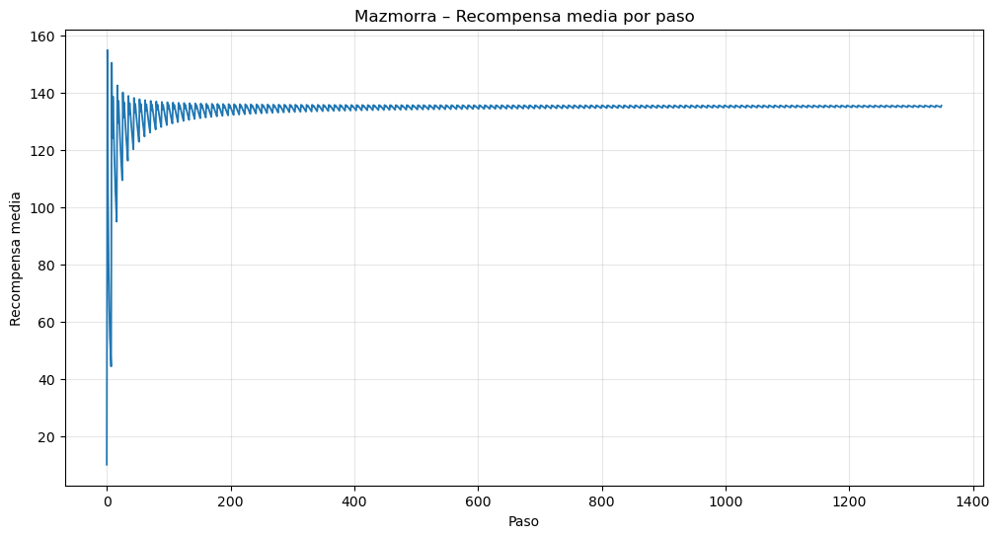

In [71]:
plt.figure(figsize=(12,6))
plt.plot(curva, lw=1.3)
plt.title("Mazmorra – Recompensa media por paso")
plt.xlabel("Paso")
plt.ylabel("Recompensa media")
plt.grid(alpha=0.3)

Parecido pero tarda un poco menos en encontrar el camino optimo y la recompensa media es mas alta por ser una aventura más fácil

**Como la tercera** no tiene una batalla no determinada de ante mano y más laberinto el mismo enviroment debería de valer

In [72]:
mdp_aventura = cargar_aventura_mdp(json.load(open('Aventura3.json')))
env3 = Aventura2GymEnv(mdp_aventura)


agente = QLearningAgent(env3)

# Entrenar al agente
agente.entrenar(episodios=1000)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: 10.0
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Capítulo 0, Estado: 4, Recompensa: 10.0
Estado actual: 4
Acciones disponibles: [26, 5]
Tamaño del action_space: 2
Acción seleccionada: 26, Siguiente estado: 26
Capítulo 0, Estado: 26, Recompensa: -1000.0
Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Estado actual: 4
Acciones disponibles: [26, 5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Estado actual: 5
Acciones disponibles: [6, 7, 8, 9]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Estado actual: 6
Acciones disponibles: [10, 5, 11, 12

In [73]:
agente = QLearningAgent(env3, epsilon=0.1)
agente.entrenar(episodios=1000)

curva = evaluar_curva(env3, agente, pasos=1500)

Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Capítulo 0, Estado: 2, Recompensa: 10.0
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Capítulo 0, Estado: 4, Recompensa: 10.0
Estado actual: 4
Acciones disponibles: [26, 5]
Tamaño del action_space: 2
Acción seleccionada: 26, Siguiente estado: 26
Capítulo 0, Estado: 26, Recompensa: -1000.0
Estado actual: 1
Acciones disponibles: [2, 3]
Tamaño del action_space: 2
Acción seleccionada: 2, Siguiente estado: 2
Estado actual: 2
Acciones disponibles: [4]
Tamaño del action_space: 2
Acción seleccionada: 4, Siguiente estado: 4
Estado actual: 4
Acciones disponibles: [26, 5]
Tamaño del action_space: 2
Acción seleccionada: 5, Siguiente estado: 5
Estado actual: 5
Acciones disponibles: [6, 7, 8, 9]
Tamaño del action_space: 2
Acción seleccionada: 6, Siguiente estado: 6
Estado actual: 6
Acciones disponibles: [10, 5, 11, 12

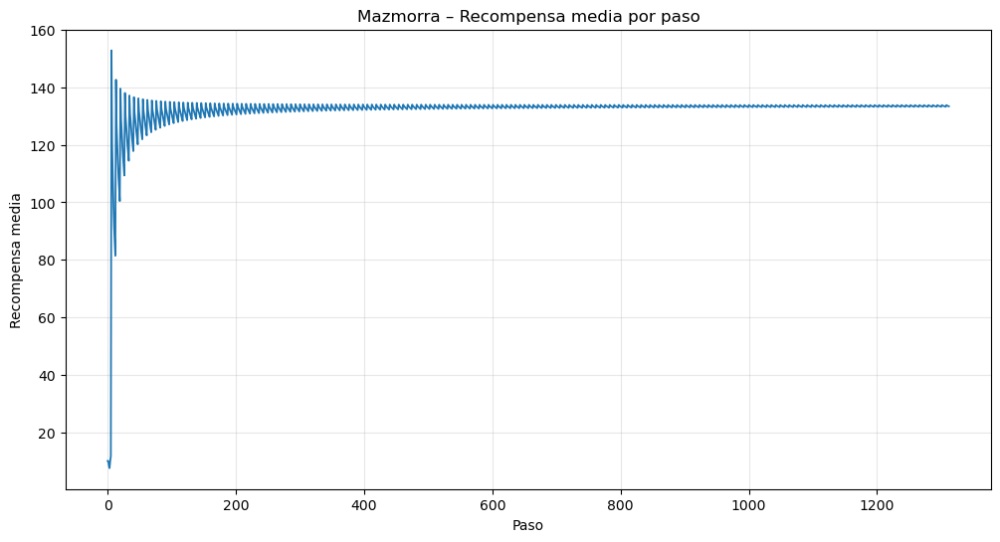

In [74]:
plt.figure(figsize=(12,6))
plt.plot(curva, lw=1.3)
plt.title("Mazmorra – Recompensa media por paso")
plt.xlabel("Paso")
plt.ylabel("Recompensa media")
plt.grid(alpha=0.3)

Vemos que hacer los nodos mas laberínticos y que tenga unos pocos más nodos no dificulta el encontrar el camino óptimo, y de hecho por no tener encuentro para el que necesites un objeto es más fácil que las otras ( en esta **coger el objeto te mataba y eso no afecto en nada al agente sobre todo porque al no ser nlp no asocio coger objeto bueno en su entrenamiento, simplemente mira caminos**). **Obviamente mis datasets son bastante cortos** y solo he usado 3, pero teniendo en cuenta que este trabajo ya me ha tomado 5 veces más tiempo que los otros de la asignatura no voy a crear dtasets más largos una vez demostrado que mi red funciona, que encuentros no determinísticos pueden ser resueltos, y que explorando una de cada 10 runs apenas tarda en encontrar el camino optimo en cyoa.